# DT-CWT modifications — notebook base (item 3)

Exploração **manual** (não treino) de modificações no domínio DT-CWT, restritas à máscara **full** via landmarks SCRFD.

Bibliotecas = `pytorch_wavelets`, `facenet_pytorch`, `insightface`/`cv2`, `torch`/`numpy`. 

Ordem incremental: (a) imports → (b) datasets → (c) landmarks+máscara → (d) DT-CWT mag/fase → (e) LBP/seed.


## (a) Imports


In [1]:
from __future__ import annotations

from pathlib import Path
import sys
import hashlib

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from skimage.feature import local_binary_pattern

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from models.face_detector import FaceDetector, LANDMARK_NAMES, get_default_detector
from models.masks import build_region_mask
from models.wavelet_transform import DTCWTDecimated
from models.embedders import FaceNetEmbedder  # disponível para métricas nas tarefas 4+

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_SIZE = 224
WAVELET_J = 3
ORIENT_LABELS = ("+15°", "+45°", "+75°", "-75°", "-45°", "-15°")

print("DEVICE", DEVICE)
print("ROOT", ROOT)


/home/dcarvalho/Lightweight-Face-De-identification/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DEVICE cuda
ROOT /home/dcarvalho/Lightweight-Face-De-identification


/home/dcarvalho/Lightweight-Face-De-identification/.venv/lib/python3.12/site-packages/pytorch_wavelets/dtcwt/coeffs.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream


## (b) Datasets (paths dos scripts / normalização)

Scripts wavelet usam LFW em `/mnt/study-data/dcarvalho/datasets/lfw/faces_{train,test}`.
Normalização (itens 1–2) grava `celebahq_pp_norm` e `lfw_norm` quando disponíveis; se a pasta `*_norm` não existir, cai no path base usado pelos scripts.


CELEBA_DIR /mnt/databases/faces/celebahq_pp_frontal (3 exemplos)
LFW_DIR    /mnt/databases/faces/lfw/faces_train (3 exemplos)
Usando EXAMPLE_PATHS:
 - img_00002.jpg
 - img_00015.jpg
 - img_00011.jpg


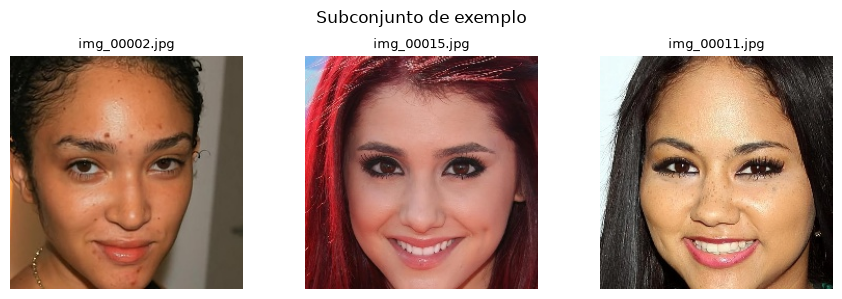

In [3]:
DATA_ROOT = Path("/mnt/databases/faces/")

def resolve_image_dir(*candidates: Path) -> Path:
    for p in candidates:
        if p.is_dir():
            return p
    raise FileNotFoundError(
        "Nenhum diretório de imagens encontrado entre: "
        + ", ".join(str(c) for c in candidates)
    )

# Preferir saída normalizada (itens 1–2); fallback = paths dos scripts / preprocess
CELEBA_DIR = resolve_image_dir(
    DATA_ROOT / "celebahq_pp_frontal",
)
LFW_DIR = resolve_image_dir(
    DATA_ROOT / "lfw" / "faces_train",
)

def list_images(folder: Path, n: int = 6) -> list[Path]:
    files = sorted(
        [p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    )
    if not files:
        raise FileNotFoundError(f"Sem imagens em {folder}")
    return files[:n]

def load_rgb_float(path: Path, size: int = IMAGE_SIZE) -> np.ndarray:
    """RGB float32 em [0, 1], HxWx3."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    if rgb.shape[0] != size or rgb.shape[1] != size:
        rgb = cv2.resize(rgb, (size, size), interpolation=cv2.INTER_AREA)
    return rgb.astype(np.float32) / 255.0

#CELEBA_PATHS = list_images(CELEBA_DIR, n=3)
#LFW_PATHS = list_images(LFW_DIR, n=3)

CELEBA_PATHS = [
    CELEBA_DIR / "img_00002.jpg",
    CELEBA_DIR / "img_00015.jpg",
    CELEBA_DIR / "img_00011.jpg",
]

LFW_PATHS = [
    LFW_DIR / "img_000002.jpg",
    LFW_DIR / "img_000010.jpg",
    LFW_DIR / "img_000030.jpg",
]

EXAMPLE_PATHS = CELEBA_PATHS  # default dos scripts wavelet; troque para CELEBA_PATHS se preferir
EXAMPLE_IMAGES = [load_rgb_float(p) for p in EXAMPLE_PATHS]

print("CELEBA_DIR", CELEBA_DIR, f"({len(CELEBA_PATHS)} exemplos)")
print("LFW_DIR   ", LFW_DIR, f"({len(LFW_PATHS)} exemplos)")
print("Usando EXAMPLE_PATHS:")
for p in EXAMPLE_PATHS:
    print(" -", p.name)

fig, axes = plt.subplots(1, len(EXAMPLE_IMAGES), figsize=(3 * len(EXAMPLE_IMAGES), 3))
if len(EXAMPLE_IMAGES) == 1:
    axes = [axes]
for ax, img, path in zip(axes, EXAMPLE_IMAGES, EXAMPLE_PATHS):
    ax.imshow(img)
    ax.set_title(path.name, fontsize=9)
    ax.axis("off")
plt.suptitle("Subconjunto de exemplo")
plt.tight_layout()
plt.show()


## (c) Landmarks (SCRFD) + máscara full

Reusa `models/face_detector.py` e `models/masks.build_region_mask(..., regions=(\"full\",))`.


In [ ]:
detector = get_default_detector()

def detect_and_full_mask(rgb: np.ndarray, det: FaceDetector = detector):
    """rgb [0,1] HxWx3 → landmarks (5,2), mask torch [1,1,H,W]."""
    h, w = rgb.shape[:2]
    bgr_u8 = cv2.cvtColor((rgb * 255.0).clip(0, 255).astype(np.uint8), cv2.COLOR_RGB2BGR)
    best = det.detect_best(bgr_u8)
    if best is None:
        raise RuntimeError("Nenhuma face detectada")
    landmarks = best.landmarks.astype(np.float32)
    mask = build_region_mask(
        landmarks, ("full",), h, w, device=torch.device("cpu")
    )
    return landmarks, mask, float(best.score)

# Uma imagem principal para as células seguintes (índice 0 do subset)
img0 = EXAMPLE_IMAGES[1]
path0 = EXAMPLE_PATHS[0]
landmarks0, mask0, score0 = detect_and_full_mask(img0)
mask0_np = mask0.squeeze().numpy()

print(path0.name, "det_score", f"{score0:.3f}")
for name, (x, y) in zip(LANDMARK_NAMES, landmarks0):
    print(f"  {name}: ({x:.1f}, {y:.1f})")
print("mask shape", mask0.shape, "mean", float(mask0_np.mean()))

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img0)
axes[0].scatter(landmarks0[:, 0], landmarks0[:, 1], c="lime", s=30, zorder=3)
for name, (x, y) in zip(LANDMARK_NAMES, landmarks0):
    axes[0].annotate(name, (x, y), color="yellow", fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[0].set_title("original + landmarks")
axes[0].axis("off")

overlay = img0.copy()
m = mask0_np[..., None]
overlay = overlay * (1.0 - 0.45 * m) + np.array([1.0, 0.2, 0.2], dtype=np.float32) * (0.45 * m)
axes[1].imshow(np.clip(overlay, 0, 1))
axes[1].contour(mask0_np, levels=[0.5], colors="cyan", linewidths=1.2)
axes[1].set_title("máscara full sobreposta")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## (d) DT-CWT J=3 — magnitude e fase por nível × orientação

Usa `DTCWTDecimated` (`pytorch_wavelets`). Coeficientes de detalhe: `[B,C,6,H,W,2]` (real/imag).


In [ ]:
wavelet = DTCWTDecimated(J=WAVELET_J)

x0 = torch.from_numpy(img0).permute(2, 0, 1).unsqueeze(0).float()  # [1,3,H,W]
with torch.no_grad():
    Yl0, Yh0 = wavelet(x0)

print("Yl", tuple(Yl0.shape), Yl0.dtype)
for j, yh in enumerate(Yh0):
    print(f"Yh[{j}]", tuple(yh.shape), yh.dtype)

# Magnitude/fase no canal de luminância aproximada (média RGB) para visualização
def yh_mag_phase_gray(yh: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:
    """yh [1,3,6,H,W,2] → mag, phase [6,H,W] (média nos canais RGB)."""
    c = torch.view_as_complex(yh.contiguous())  # [1,3,6,H,W]
    c_gray = c.mean(dim=1).squeeze(0)  # [6,H,W]
    return torch.abs(c_gray).numpy(), torch.angle(c_gray).numpy()

n_levels = len(Yh0)
n_ori = 6
fig, axes = plt.subplots(n_levels, n_ori, figsize=(2.2 * n_ori, 2.2 * n_levels))
for j in range(n_levels):
    mag, _ = yh_mag_phase_gray(Yh0[j])
    for o in range(n_ori):
        ax = axes[j, o]
        ax.imshow(mag[o], cmap="magma")
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_title(ORIENT_LABELS[o], fontsize=9)
        if o == 0:
            ax.set_ylabel(f"nível {j}\n{mag.shape[1]}×{mag.shape[2]}", fontsize=8)
plt.suptitle("Magnitude |Yh| (média RGB)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(n_levels, n_ori, figsize=(2.2 * n_ori, 2.2 * n_levels))
for j in range(n_levels):
    _, phase = yh_mag_phase_gray(Yh0[j])
    for o in range(n_ori):
        ax = axes[j, o]
        ax.imshow(phase[o], cmap="twilight", vmin=-np.pi, vmax=np.pi)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_title(ORIENT_LABELS[o], fontsize=9)
        if o == 0:
            ax.set_ylabel(f"nível {j}", fontsize=8)
plt.suptitle("Fase ∠Yh (média RGB)")
plt.tight_layout()
plt.show()


## (e) Textura LBP + seed (`skimage`)

LBP via `skimage.feature.local_binary_pattern` (P=8, R=1, method=`default`). Histograma restrito à máscara full → descritor → seed determinística.


In [ ]:
LBP_P, LBP_R = 8, 1

def lbp_histogram(gray_u8: np.ndarray, mask: np.ndarray | None = None, n_bins: int = 256) -> tuple[np.ndarray, np.ndarray]:
    """LBP via skimage; hist densid. restrito à máscara. Retorna (hist, codes)."""
    codes = local_binary_pattern(gray_u8, P=LBP_P, R=LBP_R, method="default")
    codes_u8 = np.clip(codes, 0, n_bins - 1).astype(np.uint8)
    if mask is not None:
        m = mask.astype(bool) if mask.dtype != bool else mask
        vals = codes_u8[m]
    else:
        vals = codes_u8.ravel()
    hist, _ = np.histogram(vals, bins=n_bins, range=(0, n_bins), density=True)
    return hist.astype(np.float64), codes_u8

def texture_seed_from_hist(hist: np.ndarray, nbytes: int = 8) -> int:
    """Seed uint64 determinística a partir do histograma LBP."""
    digest = hashlib.sha256(hist.tobytes()).digest()[:nbytes]
    return int.from_bytes(digest, byteorder="little", signed=False)

# 2–3 imagens: usa EXAMPLE_IMAGES; máscara full só recalculada se ainda não for a img0
texture_rows = []
fig, axes = plt.subplots(len(EXAMPLE_IMAGES), 3, figsize=(9, 3 * len(EXAMPLE_IMAGES)))
if len(EXAMPLE_IMAGES) == 1:
    axes = np.expand_dims(axes, 0)

for i, (rgb, path) in enumerate(zip(EXAMPLE_IMAGES, EXAMPLE_PATHS)):
    if i == 0:
        landmarks_i, mask_i = landmarks0, mask0_np
    else:
        landmarks_i, mask_t, _ = detect_and_full_mask(rgb)
        mask_i = mask_t.squeeze().numpy()

    gray = cv2.cvtColor((rgb * 255.0).clip(0, 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    hist, codes = lbp_histogram(gray, mask=mask_i > 0.5)
    seed = texture_seed_from_hist(hist)
    entropy = float(-(hist[hist > 0] * np.log2(hist[hist > 0])).sum())
    texture_rows.append({
        "image": path.name,
        "seed": seed,
        "hist_entropy_bits": entropy,
        "hist_max": float(hist.max()),
        "hist_nonzero": int((hist > 0).sum()),
        "mask_frac": float((mask_i > 0.5).mean()),
    })

    axes[i, 0].imshow(rgb); axes[i, 0].set_title(path.name, fontsize=9); axes[i, 0].axis("off")
    axes[i, 1].imshow(codes, cmap="gray"); axes[i, 1].set_title("LBP (skimage)"); axes[i, 1].axis("off")
    axes[i, 2].bar(np.arange(256), hist, width=1.0, color="steelblue")
    axes[i, 2].set_title(f"hist (seed={seed & 0xFFFF:04x}…)")
    axes[i, 2].set_xlim(0, 255)

plt.suptitle(f"LBP P={LBP_P} R={LBP_R} method=default (máscara full)")
plt.tight_layout()
plt.show()

print("Resumo textura / seed:")
for row in texture_rows:
    print(
        f"  {row['image']}: seed={row['seed']}  entropy={row['hist_entropy_bits']:.2f} bit  "
        f"nonzero_bins={row['hist_nonzero']}  mask_frac={row['mask_frac']:.3f}"
    )

seeds = [r["seed"] for r in texture_rows]
print("seeds únicas?", len(set(seeds)) == len(seeds))


## (f) Aleatorização total de fase — item 4

Substitui a fase de **todos** os coeficientes de detalhe (J níveis × 6 orientações) por \(\varphi' \sim \mathcal{U}[-\pi,\pi]\) **dentro** da máscara full; magnitude intacta. Fora da máscara: imagem original.

Reusa `wavelet` / `DTCWTDecimated` da célula (d), `detect_and_full_mask` / máscaras da (c), paths da (b). FaceNet + `ssim_index` do projeto.


In [ ]:
import torch.nn.functional as F
from losses.losses import ssim_index, ssim_index_masked

# FaceNet (mesmo do projeto); carregar uma vez
facenet = FaceNetEmbedder(pretrained="vggface2").to(DEVICE).eval()
for p in facenet.parameters():
    p.requires_grad_(False)

# DT-CWT da célula (d) precisa estar no mesmo device das imagens
wavelet = wavelet.to(DEVICE)


def rgb_to_batch(rgb: np.ndarray) -> torch.Tensor:
    """HxWx3 float[0,1] → [1,3,H,W] no DEVICE."""
    return torch.from_numpy(np.asarray(rgb, dtype=np.float32)).permute(2, 0, 1).unsqueeze(0).to(DEVICE)


def batch_to_rgb(x: torch.Tensor) -> np.ndarray:
    return x.detach().cpu().squeeze(0).permute(1, 2, 0).clamp(0.0, 1.0).numpy()


def dtcwt_forward(x: torch.Tensor):
    """Decompõe com o `wavelet` da célula (d) (mesmo device de x)."""
    # buffers dos filtros: garantir device
    buf = next(wavelet.buffers(), None)
    if buf is not None and buf.device != x.device:
        wavelet.to(x.device)
    return wavelet(x)


def dtcwt_inverse(Yl, Yh) -> torch.Tensor:
    """Reconstrói e clampeia para [0,1]."""
    y = wavelet.inverse(Yl, Yh)
    if torch.is_complex(y):
        y = y.real
    return y.clamp(0.0, 1.0)


def downsample_mask(mask: torch.Tensor, size_hw: tuple[int, int]) -> torch.Tensor:
    """mask [1,1,H,W] → [1,1,h,w] (bilinear + limiar 0.5)."""
    m = F.interpolate(mask.float(), size=size_hw, mode="bilinear", align_corners=False)
    return (m > 0.5).to(dtype=torch.bool)


def randomize_phase_yh(Yh: list, mask_full: torch.Tensor, rng: np.random.Generator) -> list:
    """
    Substitui fase por U[-π,π] onde a máscara full (downsampled) é True.
    Yh[j]: [B,C,6,h,w,2] real/imag. Magnitude preservada.
    """
    out = []
    for yh in Yh:
        c = torch.view_as_complex(yh.contiguous())  # [B,C,6,h,w]
        mag = torch.abs(c)
        phase = torch.angle(c)
        h, w = c.shape[-2:]
        m = downsample_mask(mask_full.to(c.device), (h, w))  # [1,1,h,w]
        m = m.expand_as(phase)  # broadcast → [B,C,6,h,w]

        rand_phase = torch.tensor(
            rng.uniform(-np.pi, np.pi, size=tuple(c.shape)),
            device=c.device,
            dtype=phase.dtype,
        )
        new_phase = torch.where(m, rand_phase, phase)
        new_c = mag * torch.exp(1j * new_phase)
        out.append(torch.view_as_real(new_c))
    return out


def blend_with_mask(y_mod: torch.Tensor, x: torch.Tensor, mask_full: torch.Tensor) -> torch.Tensor:
    """Fora da máscara: pixels da original."""
    m = mask_full.to(y_mod.device).float()
    return (y_mod * m + x * (1.0 - m)).clamp(0.0, 1.0)


@torch.no_grad()
def embedding_metrics(x: torch.Tensor, y: torch.Tensor) -> tuple[float, float]:
    e1 = F.normalize(facenet(x), dim=1)
    e2 = F.normalize(facenet(y), dim=1)
    cos = float((e1 * e2).sum(dim=1).mean().item())
    euclid = float(np.sqrt(max(0.0, 2.0 * (1.0 - cos))))
    return cos, euclid


@torch.no_grad()
def ssim_metrics(x: torch.Tensor, y: torch.Tensor, mask_full: torch.Tensor) -> tuple[float, float]:
    s_full = float(ssim_index(x, y).mean().item())
    s_mask = float(ssim_index_masked(x, y, mask_full).mean().item())
    return s_full, s_mask


print("Helpers fase-random + métricas prontos. FaceNet/wavelet em", DEVICE)

# rng padrão para demo item 4 (img0); recriado no demo se texture_rows existir
def make_rng0():
    if "texture_rows" in globals() and texture_rows:
        seed = int(texture_rows[0]["seed"] & 0xFFFFFFFF)
    else:
        gray = cv2.cvtColor((img0 * 255.0).clip(0, 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
        hist, _ = lbp_histogram(gray, mask=mask0_np > 0.5)
        seed = int(texture_seed_from_hist(hist) & 0xFFFFFFFF)
    return np.random.default_rng(seed)

try:
    rng0 = make_rng0()
except NameError:
    rng0 = np.random.default_rng(0)



### Validação em 1 imagem (original | reconstrução fiel | fase aleatória)

Usa `img0` / `mask0` da tarefa 3 quando possível; seed do LBP da img0 se `texture_rows` existir.


In [ ]:
# FIX_RNG0: esta celula define rng0 antes do uso
# Demo item 4: IDT-CWT vs fase aleatória (máscara full), 1 imagem
x0_t = rgb_to_batch(img0)
mask0_t = mask0.to(DEVICE)

# seed LBP → rng0 (necessário para fase aleatória)
if "texture_rows" in globals() and texture_rows:
    seed0 = int(texture_rows[0]["seed"] & 0xFFFFFFFF)
else:
    gray0 = cv2.cvtColor((img0 * 255.0).clip(0, 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    hist0, _ = lbp_histogram(gray0, mask=mask0_np > 0.5)
    seed0 = int(texture_seed_from_hist(hist0) & 0xFFFFFFFF)
rng0 = np.random.default_rng(seed0)

Yl_b, Yh_b = dtcwt_forward(x0_t)
y_recon = dtcwt_inverse(Yl_b, Yh_b)  # sem modificacao (fidelidade IDT-CWT)
Yh_rand = randomize_phase_yh(Yh_b, mask0_t, rng0)
y_rand_wav = dtcwt_inverse(Yl_b, Yh_rand)
y_rand = blend_with_mask(y_rand_wav, x0_t, mask0_t)

cos_id, euc_id = embedding_metrics(x0_t, y_recon)
ssim_id, ssim_id_m = ssim_metrics(x0_t, y_recon, mask0_t)
cos_r, euc_r = embedding_metrics(x0_t, y_rand)
ssim_r, ssim_r_m = ssim_metrics(x0_t, y_rand, mask0_t)

print(f"IDT-CWT (sem mod): cos={cos_id:.4f} euclid={euc_id:.4f} ssim={ssim_id:.4f} ssim_mask={ssim_id_m:.4f}")
print(f"fase U[-pi,pi] + blend: cos={cos_r:.4f} euclid={euc_r:.4f} ssim={ssim_r:.4f} ssim_mask={ssim_r_m:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(img0); axes[0].set_title("original"); axes[0].axis("off")
axes[1].imshow(batch_to_rgb(y_recon)); axes[1].set_title("IDT-CWT"); axes[1].axis("off")
axes[2].imshow(batch_to_rgb(y_rand)); axes[2].set_title("fase rand + blend"); axes[2].axis("off")
axes[3].imshow(mask0.squeeze().cpu().numpy(), cmap="gray"); axes[3].set_title("mascara full"); axes[3].axis("off")
plt.tight_layout()
plt.show()


### Tabela em 3–5 imagens de exemplo

Carrega até 5 paths de `LFW_DIR` (mesmo root da célula b). Para cada uma: landmarks+máscara full, recon fiel, fase aleatória (seed = hash LBP da imagem), métricas.


In [ ]:
PHASE_N = 5
PHASE_PATHS = list_images(CELEBA_DIR, n=PHASE_N)
PHASE_IMAGES = [load_rgb_float(p) for p in PHASE_PATHS]

rows_phase_random = []

fig, axes = plt.subplots(len(PHASE_IMAGES), 3, figsize=(10, 3.2 * len(PHASE_IMAGES)))
if len(PHASE_IMAGES) == 1:
    axes = np.expand_dims(axes, 0)

for i, (rgb, path) in enumerate(zip(PHASE_IMAGES, PHASE_PATHS)):
    # reutilizar detecção da img0 se for o mesmo arquivo
    if path.resolve() == Path(path0).resolve():
        landmarks_i, mask_np_i = landmarks0, mask0_np
    else:
        landmarks_i, mask_t_i, _ = detect_and_full_mask(rgb)
        mask_np_i = mask_t_i.squeeze().numpy()

    mask_t = torch.from_numpy(mask_np_i.astype(np.float32))[None, None].to(DEVICE)
    x_t = rgb_to_batch(rgb)

    # seed por textura LBP (máscara full)
    gray = cv2.cvtColor((rgb * 255.0).clip(0, 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    hist_i, _ = lbp_histogram(gray, mask=mask_np_i > 0.5)
    seed_i = int(texture_seed_from_hist(hist_i) & 0xFFFFFFFF)
    rng_i = np.random.default_rng(seed_i)

    Yl_i, Yh_i = dtcwt_forward(x_t)
    y_rec_i = dtcwt_inverse(Yl_i, Yh_i)
    y_rnd_i = blend_with_mask(
        dtcwt_inverse(Yl_i, randomize_phase_yh(Yh_i, mask_t, rng_i)),
        x_t,
        mask_t,
    )

    cos_rec, euc_rec = embedding_metrics(x_t, y_rec_i)
    cos_rnd, euc_rnd = embedding_metrics(x_t, y_rnd_i)
    sf_rec, sm_rec = ssim_metrics(x_t, y_rec_i, mask_t)
    sf_rnd, sm_rnd = ssim_metrics(x_t, y_rnd_i, mask_t)

    rows_phase_random.append({
        "image": path.name,
        "seed": seed_i,
        "ssim_full_recon": sf_rec,
        "ssim_mask_recon": sm_rec,
        "cos_recon": cos_rec,
        "euclid_recon": euc_rec,
        "ssim_full_rand": sf_rnd,
        "ssim_mask_rand": sm_rnd,
        "cos_rand": cos_rnd,
        "euclid_rand": euc_rnd,
    })

    axes[i, 0].imshow(rgb); axes[i, 0].set_title(path.name, fontsize=8); axes[i, 0].axis("off")
    axes[i, 1].imshow(batch_to_rgb(y_rec_i)); axes[i, 1].set_title(f"recon SSIM={sf_rec:.3f}", fontsize=8); axes[i, 1].axis("off")
    axes[i, 2].imshow(batch_to_rgb(y_rnd_i)); axes[i, 2].set_title(f"rand cos={cos_rnd:.3f} SSIM_m={sm_rnd:.3f}", fontsize=8); axes[i, 2].axis("off")

plt.suptitle("Item 4 — fase aleatória U[-π,π] (máscara full)")
plt.tight_layout()
plt.show()

print(f"{'image':20s} {'SSIM_m_rec':>10s} {'SSIM_m_rnd':>10s} {'cos_rnd':>8s} {'euclid_rnd':>10s} {'SSIM_f_rnd':>10s}")
for r in rows_phase_random:
    print(
        f"{r['image']:20s} {r['ssim_mask_recon']:10.4f} {r['ssim_mask_rand']:10.4f} "
        f"{r['cos_rand']:8.4f} {r['euclid_rand']:10.4f} {r['ssim_full_rand']:10.4f}"
    )

# médias da versão modificada
mean_cos = float(np.mean([r["cos_rand"] for r in rows_phase_random]))
mean_euc = float(np.mean([r["euclid_rand"] for r in rows_phase_random]))
mean_sm = float(np.mean([r["ssim_mask_rand"] for r in rows_phase_random]))
mean_sf = float(np.mean([r["ssim_full_rand"] for r in rows_phase_random]))
mean_sm_rec = float(np.mean([r["ssim_mask_recon"] for r in rows_phase_random]))
print(
    f"\\nMédia (fase rand, n={len(rows_phase_random)}): "
    f"SSIM_mask={mean_sm:.4f}  SSIM_full={mean_sf:.4f}  cos={mean_cos:.4f}  euclid={mean_euc:.4f}"
)
print(f"Média recon fiel SSIM_mask={mean_sm_rec:.4f} (deve ficar ≈1)")


### Notas para DECISIONS (preencher após rodar)

Esperado (hipótese): SSIM **na máscara** cai forte; cos cai / euclid sobe; reconstrução base permanece com SSIM≈1.  
`rows_phase_random` guarda a tabela para copiar em `DECISIONS.md` e para comparar com o item 5 (inversão \(\varphi+\pi\)).


## (g) Inversão local de fase — item 5

Mesma pipeline da seção (f), trocando só a transformação: $\varphi'_{j,\theta} = \varphi_{j,\theta} + \pi$ **dentro** da máscara full (determinístico; mag intacta). Equivale a negar o coeficiente complexo ($c \leftarrow -c$). Fora da máscara: imagem original.

Reusa `dtcwt_forward` / `dtcwt_inverse` / `blend_with_mask` / métricas da (f) e **as mesmas** `PHASE_PATHS` / `PHASE_IMAGES` (não recarregar outro conjunto).

In [ ]:
def invert_phase_yh(Yh: list, mask_full: torch.Tensor) -> list:
    """
    φ' = φ + π onde a máscara full (downsampled) é True.
    Yh[j]: [B,C,6,h,w,2] real/imag. Magnitude preservada. Determinístico.
    """
    out = []
    for yh in Yh:
        c = torch.view_as_complex(yh.contiguous())  # [B,C,6,h,w]
        h, w = c.shape[-2:]
        m = downsample_mask(mask_full.to(c.device), (h, w))  # [1,1,h,w]
        m = m.expand_as(c)
        # φ+π ≡ multiplicar por -1; fora da máscara mantém c
        new_c = torch.where(m, -c, c)
        out.append(torch.view_as_real(new_c))
    return out


print("Helper invert_phase_yh pronto (reusa dtcwt_*/blend/métricas da seção f).")

### Demo 1 imagem (mesma `img0` / máscara da seção anterior)

In [ ]:
# Demo item 5: IDT-CWT vs fase invertida (φ+π), 1 imagem
x0_t = rgb_to_batch(img0)
mask0_t = mask0.to(DEVICE)

Yl_b, Yh_b = dtcwt_forward(x0_t)
y_recon = dtcwt_inverse(Yl_b, Yh_b)  # sem modificação (fidelidade IDT-CWT)
Yh_inv = invert_phase_yh(Yh_b, mask0_t)
y_inv_wav = dtcwt_inverse(Yl_b, Yh_inv)
y_inv = blend_with_mask(y_inv_wav, x0_t, mask0_t)

cos_id, euc_id = embedding_metrics(x0_t, y_recon)
ssim_id, ssim_id_m = ssim_metrics(x0_t, y_recon, mask0_t)
cos_i, euc_i = embedding_metrics(x0_t, y_inv)
ssim_i, ssim_i_m = ssim_metrics(x0_t, y_inv, mask0_t)

print(f"IDT-CWT (sem mod): cos={cos_id:.4f} euclid={euc_id:.4f} ssim={ssim_id:.4f} ssim_mask={ssim_id_m:.4f}")
print(f"fase φ+π + blend:  cos={cos_i:.4f} euclid={euc_i:.4f} ssim={ssim_i:.4f} ssim_mask={ssim_i_m:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(img0); axes[0].set_title("original"); axes[0].axis("off")
axes[1].imshow(batch_to_rgb(y_recon)); axes[1].set_title("IDT-CWT"); axes[1].axis("off")
axes[2].imshow(batch_to_rgb(y_inv)); axes[2].set_title("fase φ+π + blend"); axes[2].axis("off")
axes[3].imshow(mask0.squeeze().cpu().numpy(), cmap="gray"); axes[3].set_title("máscara full"); axes[3].axis("off")
plt.tight_layout()
plt.show()

### Tabela nas mesmas imagens da tarefa 4

Reutiliza `PHASE_PATHS` / `PHASE_IMAGES` já carregados (não chama `list_images` de novo). Mesma máscara full + recon fiel; só troca `randomize_phase_yh` → `invert_phase_yh`.

In [ ]:
# Mesmas PHASE_PATHS / PHASE_IMAGES da seção (f) — não recarregar
assert "PHASE_PATHS" in dir() and "PHASE_IMAGES" in dir(), (
    "Rode antes a célula de tabela da seção (f) para definir PHASE_PATHS/PHASE_IMAGES."
)

rows_phase_invert = []

fig, axes = plt.subplots(len(PHASE_IMAGES), 3, figsize=(10, 3.2 * len(PHASE_IMAGES)))
if len(PHASE_IMAGES) == 1:
    axes = np.expand_dims(axes, 0)

for i, (rgb, path) in enumerate(zip(PHASE_IMAGES, PHASE_PATHS)):
    if path.resolve() == Path(path0).resolve():
        landmarks_i, mask_np_i = landmarks0, mask0_np
    else:
        landmarks_i, mask_t_i, _ = detect_and_full_mask(rgb)
        mask_np_i = mask_t_i.squeeze().numpy()

    mask_t = torch.from_numpy(mask_np_i.astype(np.float32))[None, None].to(DEVICE)
    x_t = rgb_to_batch(rgb)

    Yl_i, Yh_i = dtcwt_forward(x_t)
    y_rec_i = dtcwt_inverse(Yl_i, Yh_i)
    y_inv_i = blend_with_mask(
        dtcwt_inverse(Yl_i, invert_phase_yh(Yh_i, mask_t)),
        x_t,
        mask_t,
    )

    cos_rec, euc_rec = embedding_metrics(x_t, y_rec_i)
    cos_inv, euc_inv = embedding_metrics(x_t, y_inv_i)
    sf_rec, sm_rec = ssim_metrics(x_t, y_rec_i, mask_t)
    sf_inv, sm_inv = ssim_metrics(x_t, y_inv_i, mask_t)

    rows_phase_invert.append({
        "image": path.name,
        "ssim_full_recon": sf_rec,
        "ssim_mask_recon": sm_rec,
        "cos_recon": cos_rec,
        "euclid_recon": euc_rec,
        "ssim_full_inv": sf_inv,
        "ssim_mask_inv": sm_inv,
        "cos_inv": cos_inv,
        "euclid_inv": euc_inv,
    })

    axes[i, 0].imshow(rgb); axes[i, 0].set_title(path.name, fontsize=8); axes[i, 0].axis("off")
    axes[i, 1].imshow(batch_to_rgb(y_rec_i)); axes[i, 1].set_title(f"recon SSIM={sf_rec:.3f}", fontsize=8); axes[i, 1].axis("off")
    axes[i, 2].imshow(batch_to_rgb(y_inv_i)); axes[i, 2].set_title(f"φ+π cos={cos_inv:.3f} SSIM_m={sm_inv:.3f}", fontsize=8); axes[i, 2].axis("off")

plt.suptitle("Item 5 — fase invertida φ+π (máscara full)")
plt.tight_layout()
plt.show()

print(f"{'image':20s} {'SSIM_m_rec':>10s} {'SSIM_m_inv':>10s} {'cos_inv':>8s} {'euclid_inv':>10s} {'SSIM_f_inv':>10s}")
for r in rows_phase_invert:
    print(
        f"{r['image']:20s} {r['ssim_mask_recon']:10.4f} {r['ssim_mask_inv']:10.4f} "
        f"{r['cos_inv']:8.4f} {r['euclid_inv']:10.4f} {r['ssim_full_inv']:10.4f}"
    )

mean_cos_i = float(np.mean([r["cos_inv"] for r in rows_phase_invert]))
mean_euc_i = float(np.mean([r["euclid_inv"] for r in rows_phase_invert]))
mean_sm_i = float(np.mean([r["ssim_mask_inv"] for r in rows_phase_invert]))
mean_sf_i = float(np.mean([r["ssim_full_inv"] for r in rows_phase_invert]))
mean_sm_rec_i = float(np.mean([r["ssim_mask_recon"] for r in rows_phase_invert]))
print(
    f"\nMédia (fase φ+π, n={len(rows_phase_invert)}): "
    f"SSIM_mask={mean_sm_i:.4f}  SSIM_full={mean_sf_i:.4f}  cos={mean_cos_i:.4f}  euclid={mean_euc_i:.4f}"
)
print(f"Média recon fiel SSIM_mask={mean_sm_rec_i:.4f} (deve ficar ≈1)")

### Comparativo tarefa 4 vs tarefa 5 (mesmas imagens)

Lado a lado: aleatorização $U[-\pi,\pi]$ (`rows_phase_random`) vs inversão $\varphi+\pi$ (`rows_phase_invert`). Preencher `DECISIONS.md` após validação visual (ruído vs. “negativo estrutural”).

In [ ]:
assert "rows_phase_random" in dir() and len(rows_phase_random) > 0, "Rode a tabela da seção (f) primeiro."
assert "rows_phase_invert" in dir() and len(rows_phase_invert) > 0, "Rode a tabela da seção (g) primeiro."
assert len(rows_phase_random) == len(rows_phase_invert), "Número de imagens diferente entre (f) e (g)."

by_inv = {r["image"]: r for r in rows_phase_invert}

print(
    f"{'image':20s} "
    f"{'cos_rnd':>8s} {'cos_inv':>8s} "
    f"{'euc_rnd':>8s} {'euc_inv':>8s} "
    f"{'SSm_rnd':>8s} {'SSm_inv':>8s} "
    f"{'SSf_rnd':>8s} {'SSf_inv':>8s}"
)
rows_compare = []
for r in rows_phase_random:
    ri = by_inv[r["image"]]
    row = {
        "image": r["image"],
        "cos_rand": r["cos_rand"],
        "cos_inv": ri["cos_inv"],
        "euclid_rand": r["euclid_rand"],
        "euclid_inv": ri["euclid_inv"],
        "ssim_mask_rand": r["ssim_mask_rand"],
        "ssim_mask_inv": ri["ssim_mask_inv"],
        "ssim_full_rand": r["ssim_full_rand"],
        "ssim_full_inv": ri["ssim_full_inv"],
    }
    rows_compare.append(row)
    print(
        f"{row['image']:20s} "
        f"{row['cos_rand']:8.4f} {row['cos_inv']:8.4f} "
        f"{row['euclid_rand']:8.4f} {row['euclid_inv']:8.4f} "
        f"{row['ssim_mask_rand']:8.4f} {row['ssim_mask_inv']:8.4f} "
        f"{row['ssim_full_rand']:8.4f} {row['ssim_full_inv']:8.4f}"
    )

def _mean(key):
    return float(np.mean([r[key] for r in rows_compare]))

print(
    f"\nMédia n={len(rows_compare)}:\n"
    f"  rand  U[-π,π]: cos={_mean('cos_rand'):.4f}  euclid={_mean('euclid_rand'):.4f}  "
    f"SSIM_mask={_mean('ssim_mask_rand'):.4f}  SSIM_full={_mean('ssim_full_rand'):.4f}\n"
    f"  inv   φ+π:     cos={_mean('cos_inv'):.4f}  euclid={_mean('euclid_inv'):.4f}  "
    f"SSIM_mask={_mean('ssim_mask_inv'):.4f}  SSIM_full={_mean('ssim_full_inv'):.4f}"
)

# quem derruba mais identidade / qualidade
winner_id = "rand U[-π,π]" if _mean("cos_rand") < _mean("cos_inv") else "inv φ+π"
winner_ssim = "rand U[-π,π]" if _mean("ssim_mask_rand") < _mean("ssim_mask_inv") else "inv φ+π"
print(f"\nMenor cos (mais desid.): {winner_id}")
print(f"Menor SSIM_mask (mais dano estrutural): {winner_ssim}")
print("Copiar médias + observação visual (ruído vs negativo estrutural) para DECISIONS.md.")